In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

BASE_DIR = Path.cwd().parent

products = pd.read_csv(BASE_DIR / "data/cleaned/products_clean.csv")
inventory = pd.read_csv(BASE_DIR / "data/cleaned/inventory_clean.csv")
sales = pd.read_csv(BASE_DIR / "data/cleaned/sales_clean.csv")
suppliers = pd.read_csv(BASE_DIR / "data/cleaned/suppliers_clean.csv")

sales["date"] = pd.to_datetime(sales["date"])

print("Datasets loaded successfully!")

print("Products:", products.shape)
print("Inventory:", inventory.shape)
print("Sales:", sales.shape)

Datasets loaded successfully!
Products: (20, 7)
Inventory: (60, 4)
Sales: (7300, 4)


In [2]:
# Calculate annual sales quantity for each product
annual_sales = (
    sales.groupby("product_id")["units_sold"]
    .sum()
    .reset_index(name="annual_units_sold")
)

# Add product cost
abc = annual_sales.merge(
    products[["product_id", "product_name", "unit_cost"]],
    on="product_id",
    how="left"
)

# Calculate annual consumption value
abc["annual_consumption_value"] = (
    abc["annual_units_sold"] * abc["unit_cost"]
)

# Sort products by value
abc = abc.sort_values(
    "annual_consumption_value",
    ascending=False
).reset_index(drop=True)

# Calculate cumulative percentage
total_value = abc["annual_consumption_value"].sum()

abc["cumulative_percentage"] = (
    abc["annual_consumption_value"].cumsum()
    / total_value * 100
)

# Classify products
abc["abc_category"] = np.where(
    abc["cumulative_percentage"] <= 80, "A",
    np.where(abc["cumulative_percentage"] <= 95, "B", "C")
)

abc

,product_id,annual_units_sold,product_name,unit_cost,annual_consumption_value,cumulative_percentage,abc_category
0,6,1847,Printer,710,1311370,11.196261,A
1,17,1805,Smart Watch,673,1214765,21.567724,A
2,19,1790,Graphics Card,671,1201090,31.822432,A
3,8,1833,Router,624,1143792,41.587940,A
4,10,1855,Tablet,476,882980,49.126678,A
5,13,1794,RAM,468,839592,56.294976,A
6,2,1794,Mouse,445,798330,63.110986,A
7,15,1843,Speaker,382,704026,69.121844,A
8,12,1871,SSD,340,636140,74.553102,A
9,20,1780,Hard Drive,318,566040,79.385858,A


In [3]:
# Calculate total daily demand per product
daily_demand = (
    sales.groupby(["date", "product_id"])["units_sold"]
    .sum()
    .reset_index()
)

# Calculate average and standard deviation
demand_stats = (
    daily_demand.groupby("product_id")["units_sold"]
    .agg(
        average_daily_demand="mean",
        demand_std="std"
    )
    .reset_index()
)

demand_stats.head()

,product_id,average_daily_demand,demand_std
0,1,4.969863,2.235250
1,2,4.915068,2.116372
2,3,4.865753,2.318358
3,4,5.073973,2.161732
4,5,5.032877,2.439153


In [4]:
# Connect products with supplier lead times
optimization = products.merge(
    suppliers[["supplier_id", "expected_lead_time_days"]],
    on="supplier_id",
    how="left"
)

# Add demand statistics
optimization = optimization.merge(
    demand_stats,
    on="product_id",
    how="left"
)

# Calculate safety stock
Z = 1.65

optimization["safety_stock"] = (
    Z
    * optimization["demand_std"]
    * np.sqrt(optimization["expected_lead_time_days"])
)

# Calculate reorder point
optimization["reorder_point"] = (
    optimization["average_daily_demand"]
    * optimization["expected_lead_time_days"]
    + optimization["safety_stock"]
)

optimization[
    [
        "product_id",
        "product_name",
        "average_daily_demand",
        "expected_lead_time_days",
        "safety_stock",
        "reorder_point"
    ]
]

,product_id,product_name,average_daily_demand,expected_lead_time_days,safety_stock,reorder_point
0,1,Laptop,4.969863,12,12.776169,72.414525
1,2,Mouse,4.915068,15,13.524511,87.250539
2,3,Keyboard,4.865753,12,13.251198,71.640239
3,4,Monitor,5.073973,15,13.814380,89.923969
4,5,Headphones,5.032877,6,9.858221,40.055481
5,6,Printer,5.060274,7,9.573812,44.995730
6,7,Webcam,4.983562,15,15.458190,90.211614
7,8,Router,5.021918,12,12.681529,72.944543
8,9,Smartphone,4.791781,6,9.166048,37.916733
9,10,Tablet,5.082192,15,14.373707,90.606584


In [5]:
current_stock = (
    inventory.groupby("product_id")["stock_quantity"]
    .sum()
    .reset_index(name="current_stock")
)

optimization = optimization.merge(
    current_stock,
    on="product_id",
    how="left"
)

# Target stock: lead time + 14 days of demand
optimization["target_stock"] = (
    optimization["average_daily_demand"]
    * (optimization["expected_lead_time_days"] + 14)
    + optimization["safety_stock"]
)

# Suggested replenishment quantity
optimization["suggested_order_quantity"] = np.ceil(
    (
        optimization["target_stock"]
        - optimization["current_stock"]
    ).clip(lower=0)
).astype(int)

# Reorder status
optimization["reorder_status"] = np.where(
    optimization["current_stock"] <= optimization["reorder_point"],
    "Reorder Required",
    "Sufficient Stock"
)

optimization[
    [
        "product_name",
        "current_stock",
        "reorder_point",
        "target_stock",
        "suggested_order_quantity",
        "reorder_status"
    ]
]

,product_name,current_stock,reorder_point,target_stock,suggested_order_quantity,reorder_status
0,Laptop,486,72.414525,141.992607,0,Sufficient Stock
1,Mouse,254,87.250539,156.061498,0,Sufficient Stock
2,Keyboard,475,71.640239,139.760787,0,Sufficient Stock
3,Monitor,378,89.923969,160.959585,0,Sufficient Stock
4,Headphones,423,40.055481,110.515755,0,Sufficient Stock
5,Printer,573,44.995730,115.839566,0,Sufficient Stock
6,Webcam,441,90.211614,159.981477,0,Sufficient Stock
7,Router,451,72.944543,143.251392,0,Sufficient Stock
8,Smartphone,239,37.916733,105.001665,0,Sufficient Stock
9,Tablet,454,90.606584,161.757268,0,Sufficient Stock


In [6]:
final_analysis = optimization.merge(
    abc[["product_id", "abc_category", "annual_consumption_value"]],
    on="product_id",
    how="left"
)

final_analysis = final_analysis.sort_values(
    ["reorder_status", "abc_category"],
    ascending=[True, True]
)

final_analysis[
    [
        "product_name",
        "abc_category",
        "annual_consumption_value",
        "current_stock",
        "reorder_point",
        "suggested_order_quantity",
        "reorder_status"
    ]
]

,product_name,abc_category,annual_consumption_value,current_stock,reorder_point,suggested_order_quantity,reorder_status
1,Mouse,A,798330,254,87.250539,0,Sufficient Stock
5,Printer,A,1311370,573,44.995730,0,Sufficient Stock
7,Router,A,1143792,451,72.944543,0,Sufficient Stock
9,Tablet,A,882980,454,90.606584,0,Sufficient Stock
11,SSD,A,636140,422,45.294767,0,Sufficient Stock
12,RAM,A,839592,294,54.130064,0,Sufficient Stock
14,Speaker,A,704026,528,72.639199,0,Sufficient Stock
16,Smart Watch,A,1214765,399,88.588310,0,Sufficient Stock
18,Graphics Card,A,1201090,528,87.739309,0,Sufficient Stock
19,Hard Drive,A,566040,622,86.991228,0,Sufficient Stock


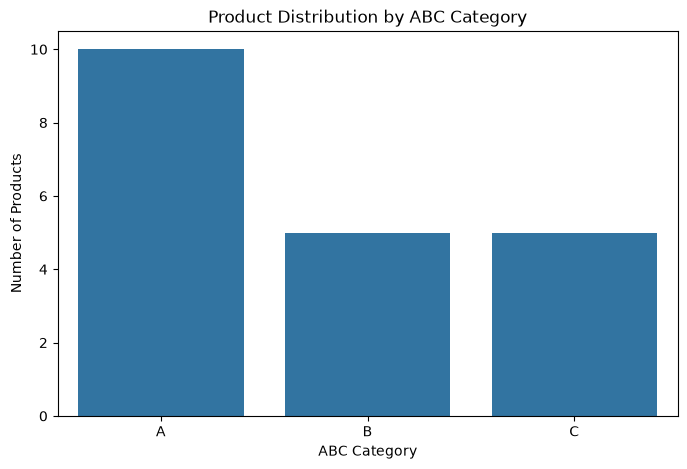

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=final_analysis,
    x="abc_category",
    order=["A", "B", "C"]
)

plt.title("Product Distribution by ABC Category")
plt.xlabel("ABC Category")
plt.ylabel("Number of Products")

plt.show()

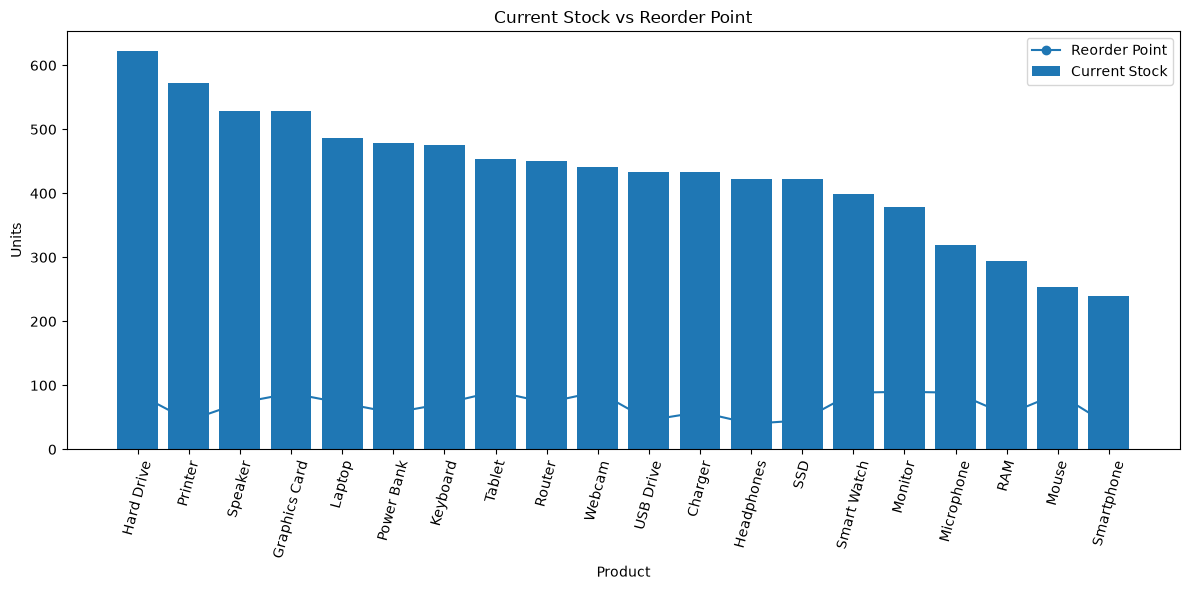

In [8]:
plot_data = final_analysis.sort_values(
    "current_stock",
    ascending=False
)

plt.figure(figsize=(12, 6))

plt.bar(
    plot_data["product_name"],
    plot_data["current_stock"],
    label="Current Stock"
)

plt.plot(
    plot_data["product_name"],
    plot_data["reorder_point"],
    marker="o",
    label="Reorder Point"
)

plt.xticks(rotation=75)
plt.title("Current Stock vs Reorder Point")
plt.xlabel("Product")
plt.ylabel("Units")
plt.legend()
plt.tight_layout()

plt.show()

In [9]:
REPORT_DIR = BASE_DIR / "reports"
REPORT_DIR.mkdir(exist_ok=True)

abc.to_csv(
    REPORT_DIR / "abc_inventory_analysis.csv",
    index=False
)

final_analysis.to_csv(
    REPORT_DIR / "inventory_optimization_results.csv",
    index=False
)

print("Step 9 completed!")
print("Reports saved successfully.")

Step 9 completed!
Reports saved successfully.
